# Generalization

Một model có thể đúng hoàn toàn trên dữ liệu đã học mà vẫn sai trên dữ liệu mới, ví dụ khi nó chỉ lưu lại các buổi cũ rồi tra bảng. Điều ta cần là đoán tốt trên mẫu chưa thấy; khả năng đó gọi là tổng quát hóa (generalization). Bài này dùng một model đơn giản để thấy underfitting (model quá đơn giản), overfitting (model học thuộc dữ liệu train) và cách đọc learning curve để quyết định nên làm gì tiếp.

> **Mục tiêu**
>
> - Phân biệt lỗi trên train với lỗi trên dữ liệu mới.
> - Nhận ra underfitting và overfitting.
> - Đọc learning curve.
> - Chọn việc làm tiếp dựa trên các dấu hiệu đó.

## Nhớ một ví dụ khác với học một quy luật

Ta tạm thu bài toán xuống một feature $x$ trong khoảng 0–1: vị trí của một buổi trong lịch hoạt động. Mức tham gia đã chuẩn hóa là

$$y=\sin(2\pi x)+\varepsilon.$$

$\sin$ tạo một xu hướng lên rồi xuống để nhìn được bằng hình. $\varepsilon$ là nhiễu, ở đây sinh ngẫu nhiên với trung bình 0 và độ lệch chuẩn 0.25. Các giá trị âm có nghĩa là thấp hơn mức tham gia chuẩn, không phải số người âm. Dạng sóng này do ta tự đặt ra để thí nghiệm, nhờ đó biết chính xác đâu là quy luật, đâu là nhiễu. Học được là nhờ có quy luật: nếu nhãn hoàn toàn ngẫu nhiên như kết quả xổ số thì không mô hình nào đoán được, dù dữ liệu nhiều đến đâu.



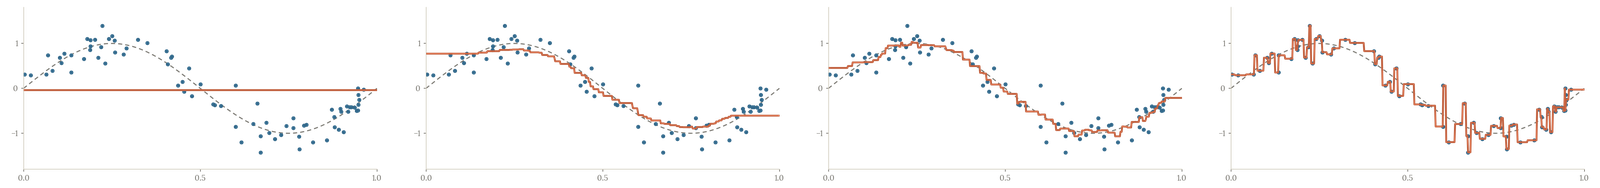

Mô hình trong hình là k-Nearest Neighbors regression, viết ngắn là kNN. Để đoán tại $x$, nó tìm $k$ điểm train gần nhất rồi lấy trung bình nhãn của chúng. Bài 2.4 sẽ học thuật toán kỹ hơn; hôm nay chỉ dùng đặc tính: $k$ nhỏ cho đường linh hoạt hơn, $k$ lớn cho đường trơn hơn.

Với $k=1$, tại một điểm train, hàng xóm gần nhất chính là nó, nên mô hình trả đúng nhãn đã quan sát. Điều ấy bao gồm cả phần nhiễu của riêng điểm đó. Với $k$ bằng toàn bộ số mẫu train, mọi vị trí nhận cùng một giá trị trung bình, dù xu hướng thật lên xuống rõ rệt.

**Hỏi nhanh.** Mô hình đoán đúng mọi nhãn trên tập train. Điều đó chứng minh được gì?

- A. Nó khớp các mẫu đã học, còn mẫu mới thì chưa biết
- B. Nó chắc chắn đã tìm ra quy luật thật
- C. Dữ liệu train chắc chắn không có nhãn nhiễu
- D. Nó sẽ đúng ít nhất 90% trên dữ liệu mới

<details><summary>Đáp án</summary>

A. Nó khớp các mẫu đã học, còn mẫu mới thì chưa biết

Khớp train chỉ là một quan sát trên dữ liệu cũ. Mô hình đủ mạnh có thể khớp cả những nhãn nhiễu, giống học thuộc đáp án đề cũ. Muốn biết khả năng tổng quát hóa, ta cần dữ liệu chưa hề được dùng để học hay để chọn phương án.

</details>

## Viết rõ đang đo lỗi ở đâu

Giả sử có $n$ mẫu train. Sai số train với MSE là

$$\widehat R_{\rm train}(f)=\frac1n\sum_{i=1}^{n}(f(x_i)-y_i)^2.$$

Nhưng điều ta thật sự cần là lỗi trên các mẫu **mới**, tức trung bình lỗi nếu đem model dùng cho rất nhiều buổi sau này:

$$R(f)=\mathbb E\big[(f(x)-y)^2\big].$$

$\mathbb E$ là kỳ vọng (bài 0.7), lấy trên mọi mẫu có thể gặp lúc dùng thật. Ta không có các mẫu đó, nên dùng tập validation để ước lượng $R(f)$. Muốn ước lượng đúng, validation phải giống dữ liệu lúc dùng thật; chia sai thì điểm có thể đẹp mà không nói lên điều ta cần. Khả năng đoán tốt trên mẫu chưa gặp lúc học gọi là tổng quát hóa, hay khái quát hóa (generalization); đó là thứ ta cần, không phải điểm trên train.

Trong thí nghiệm này, train và validation được sinh riêng từ cùng một công thức, nên validation giống hệt dữ liệu mới. Code tạo 80 mẫu train và 160 mẫu validation, rồi so ba giá trị $k$.

In [ ]:
import numpy as np
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(12)

def make_data(n):
    X = rng.uniform(0, 1, size=(n, 1))
    y = np.sin(2 * np.pi * X[:, 0]) + rng.normal(0, 0.25, size=n)
    return X, y

X_train, y_train = make_data(80)
X_valid, y_valid = make_data(160)
print(X_train.shape, y_train.shape)
for k in [80, 10, 1]:
    model = KNeighborsRegressor(n_neighbors=k).fit(X_train, y_train)
    train_mse = mean_squared_error(y_train, model.predict(X_train))
    valid_mse = mean_squared_error(y_valid, model.predict(X_valid))
    print(f"k={k:2d}: train={train_mse:.4f}, valid={valid_mse:.4f}")

(80, 1) (80,)
k=80: train=0.5861, valid=0.5654
k=10: train=0.0574, valid=0.0820
k= 1: train=0.0000, valid=0.1011


Đọc cả hai cột. Khi $k=80$, train và validation cùng có lỗi lớn: mô hình quá đơn giản để giữ xu hướng. Khi $k=1$, train có lỗi bằng 0, nhưng validation không vì thế thấp nhất. $k=10$ lấy trung bình cục bộ, giảm tác động của nhiễu mà còn giữ được dạng sóng.

Không chọn mô hình từ cột train. Cũng không biến ví dụ thành quy tắc “luôn dùng $k=10$”: số mẫu, mật độ điểm, độ nhiễu và số chiều thay đổi thì $k$ phù hợp cũng đổi.

**Hỏi nhanh.** Phương án A có MSE 0.01 trên train và 0.30 trên validation. Phương án B có MSE 0.08 trên train và 0.12 trên validation. Chọn theo validation thì ta chọn phương án nào?

- A. A, vì MSE trên train nhỏ hơn
- B. A, vì chênh lệch lớn cho thấy nó học được nhiều hơn
- C. B, vì MSE trên validation nhỏ hơn
- D. Chưa chọn được, phải xem điểm test của cả hai

<details><summary>Đáp án</summary>

C. B, vì MSE trên validation nhỏ hơn

Mục tiêu là đoán tốt mẫu mới, và validation là nơi đo điều đó. A khớp train rất sát nhưng đoán validation kém hẳn, đây là dấu hiệu cần xem kỹ. Test chỉ mở ra sau khi đã chọn xong; dùng test để chọn thì nó không còn độc lập.

</details>

## Underfit và overfit là chẩn đoán có điều kiện

**Underfitting** (học chưa đủ): model quá đơn giản, không bắt được quy luật. Ví dụ $k = 80$ san phẳng cả đường cong. Dấu hiệu: lỗi train và lỗi validation **cùng cao** và gần nhau. Thêm dữ liệu cùng loại không giúp, vì model còn chưa khớp nổi train; cần model linh hoạt hơn hoặc thêm đặc trưng tốt hơn.

**Overfitting** (học quá sát): model học thuộc cả nhiễu của train. Ví dụ $k = 1$: đổi một nhãn nhiễu là cả một đoạn dự đoán đổi theo. Dấu hiệu: lỗi train **thấp** mà lỗi validation **cao hơn hẳn**. Cách chữa: giảm độ linh hoạt (ở đây là tăng $k$), dùng regularization (chương 2), hoặc thêm dữ liệu.

Overfitting dễ xảy ra khi model có rất nhiều tham số mà dữ liệu ít, hay số đặc trưng nhiều hơn số mẫu, như 100 chỉ số xét nghiệm cho 50 bệnh nhân. Một mạng neural đủ lớn còn học thuộc được cả nhãn bị xáo ngẫu nhiên, đúng 100% trên train; vì vậy điểm train cao không chứng minh model đã học được quy luật.

Tuy vậy, hai dấu hiệu trên chỉ là gợi ý. Train tốt mà validation kém cũng có thể do dữ liệu đổi theo thời gian, một cột bị sai đơn vị, hay hai tập được xử lý khác nhau. Train và validation cùng kém cũng có thể do nhãn bị lệch hàng hay metric viết sai. Trước khi sửa model, nên kiểm lại dữ liệu và tính tay một ví dụ nhỏ.

**Hỏi nhanh.** Một mô hình phân loại review phim là khen hay chê, có 2.4 triệu tham số, học trên 5000 review. Nó đoán đúng 98.5% trên train, 72.3% trên validation và 71.8% trên test. Số liệu này chỉ ra vấn đề gì?

- A. Lộ dữ liệu, vì validation và test gần bằng nhau
- B. Underfitting, vì 72% là thấp với bài này
- C. Overfitting, vì train gần hoàn hảo còn validation kém xa
- D. Dữ liệu thay đổi, vì train cao còn test thấp

<details><summary>Đáp án</summary>

C. Overfitting, vì train gần hoàn hảo còn validation kém xa

Hai dấu hiệu cùng chỉ một hướng: validation thấp hơn train tới 26 điểm, và mô hình có 2.4 triệu tham số mà chỉ có 5000 mẫu để học. Validation gần bằng test là điều bình thường khi hai tập giống nhau, không phải dấu hiệu lộ dữ liệu. Nếu dữ liệu đã thay đổi thì validation và test sẽ lệch nhau. Underfitting thì không thể đúng 98.5% trên train. Hướng chữa là giảm độ linh hoạt của mô hình, dùng regularization ở chương 2, hoặc thêm dữ liệu.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 272](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=98)

</details>

> **Bias và variance ở mức trực giác**
>
> **Bias** là phần sai do model quá cứng nhắc, sai cùng một kiểu dù học từ bộ train nào, như $k = 80$ lần nào cũng đoán một đường phẳng. **Variance** là mức model thay đổi khi đổi sang bộ train khác, như $k = 1$ đổi theo từng điểm nhiễu. Model linh hoạt hơn thường giảm bias nhưng tăng variance. Hình dưới học năm lần trên năm bộ train khác nhau để thấy điều đó.
>
> Với MSE, lỗi trên mẫu mới tách được thành ba phần: $\mathbb E[(y-\hat f(x))^2] = \sigma^2 + \text{bias}^2 + \text{variance}$. Ở đây bias là độ lệch giữa dự đoán trung bình (lấy trên nhiều bộ train) và giá trị thật; variance là phương sai của dự đoán quanh trung bình ấy; $\sigma^2$ là phương sai của nhiễu, phần không model nào giảm được (irreducible error). Bias và variance thường đổi ngược chiều nhau khi chỉnh độ phức tạp, nhưng không phải luôn luôn: đoán bừa thì cả hai đều cao.



## Learning curve: thêm dữ liệu có đáng làm không?

Câu hỏi thực tế: có nên thu thêm dữ liệu không? **Learning curve** trả lời câu đó: giữ $k = 10$, tăng dần số mẫu train, và đo lỗi train cùng lỗi validation ở mỗi mức. Trục ngang là **số mẫu train**. (Đừng nhầm với đường loss theo số bước huấn luyện, sẽ gặp ở chương 3.)



Hàm `learning_curve` của scikit-learn làm việc này. Ở mỗi kích thước, nó chia dữ liệu thành 4 phần (gọi là 4 fold), lần lượt giữ một phần để chấm và học trên phần còn lại, rồi lấy trung bình; bài 1.3 sẽ học kỹ cách chia này.

In [ ]:
from sklearn.model_selection import KFold, learning_curve

X_curve, y_curve = make_data(400)
cv = KFold(n_splits=4, shuffle=True, random_state=12)
sizes, train_scores, valid_scores = learning_curve(
    KNeighborsRegressor(n_neighbors=10),
    X_curve, y_curve, cv=cv,
    train_sizes=[20, 60, 140, 300],
    scoring="neg_mean_squared_error",
    shuffle=True, random_state=12, n_jobs=1,
)
for size, train_score, valid_score in zip(
    sizes, train_scores.mean(axis=1), valid_scores.mean(axis=1)
):
    print(f"n={size:3d}: train MSE={-train_score:.4f}, valid MSE={-valid_score:.4f}")

n= 20: train MSE=0.2133, valid MSE=0.2187
n= 60: train MSE=0.0701, valid MSE=0.0974
n=140: train MSE=0.0602, valid MSE=0.0761
n=300: train MSE=0.0610, valid MSE=0.0748


Các score có dấu âm vì công cụ chọn mô hình của scikit-learn quy ước “lớn hơn là tốt hơn”, nên MSE được đổi dấu thành neg-MSE; ta đổi dấu lại để đọc. Mỗi hàng là trung bình của bốn fold.

Với 20 mẫu, mười hàng xóm phủ một vùng rộng nên đường dự đoán bị san phẳng, cả hai lỗi đều cao. Thêm mẫu thì vùng ấy hẹp lại, đường giữ được dạng sóng, và lỗi validation giảm. Từ 140 lên 300 mẫu, lỗi validation gần như không giảm nữa.

Cách đọc một learning curve:

- **Hai đường sát nhau và cùng đi ngang ở mức lỗi cao**: underfitting. Thêm dữ liệu không giúp; cần model mạnh hơn hoặc đặc trưng tốt hơn.
- **Hai đường cách xa, đường validation còn đang giảm**: thêm dữ liệu còn có ích.
- **Hai đường cách xa, đường validation đã đi ngang**: overfitting; nên giảm độ phức tạp hoặc thêm regularization.

Đổi tỉ lệ chia, chẳng hạn từ 70% train và 30% test sang 90% và 10%, cũng theo cách đọc này: train nhiều hơn thường giúp nhưng không chắc, còn tập chấm nhỏ đi thì con số đo được dao động nhiều hơn.

Còn một mốc để so: kể cả khi biết chính xác $\sin(2\pi x)$, lỗi vẫn còn bằng phương sai của nhiễu, $0.25^2 = 0.0625$, vì không model nào đoán được nhiễu. Validation MSE 0.0748 ở 300 mẫu đã khá gần mốc ấy, nên không còn cải thiện được bao nhiêu. Với dữ liệu thật ta không biết mức nhiễu; người ta thường lấy kết quả tốt nhất mà con người làm được, như một nhóm bác sĩ hội chẩn, làm ước lượng cho mức lỗi thấp nhất có thể, gọi là sai số Bayes.

**Hỏi nhanh.** Tăng train từ 200 lên 800 rồi 2000 mẫu. MSE trên train lần lượt là 0.42, 0.43, 0.43. MSE trên validation là 0.46, 0.45, 0.45. Cách chia và metric đều đã kiểm. Ta nên thử gì trước?

- A. Giữ nguyên mọi thứ, chỉ thu thêm mẫu
- B. Thêm feature hoặc dùng mô hình mạnh hơn
- C. Giảm độ phức tạp để thu hẹp khoảng cách
- D. Đổi seed chia dữ liệu tới khi validation thấp hơn

<details><summary>Đáp án</summary>

B. Thêm feature hoặc dùng mô hình mạnh hơn

Cả hai lỗi đều cao, gần như không đổi, và sát nhau. Đó là dấu hiệu mô hình quá đơn giản so với dữ liệu. Thêm mẫu không giúp được, còn giảm độ phức tạp chỉ làm tệ hơn. Chọn seed theo điểm là chọn lại cách đánh giá, không sửa được gì ở mô hình.
Phỏng theo: [CMU 10-601 · Practice Problems, Exam 1 · Q3.1](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam1_practice_problems.pdf#page=14)

</details>

## Ví dụ tính tay

Giữ $k=2$. Hai hàng xóm của một buổi mới có nhãn 1 và 3. Dự đoán là $(1+3)/2=2$. Nếu nhãn thật của buổi mới là 4, lỗi bình phương là $(2-4)^2=4$.

Trên ba buổi validation, nhãn thật $(1, 3, 5)$ và dự đoán $(2, 3, 4)$ cho MSE $= (1 + 0 + 1)/3 = 2/3$. Một model khác đoán đúng hết ba nhãn **train** không nói gì về ba buổi validation này. Mỗi con số lỗi phải đi kèm câu trả lời: tính trên những buổi nào?

Khi so hai model trên nhiều fold, nên xem từng fold chứ không chỉ con số trung bình. Model thắng ở mọi fold đáng tin hơn model chỉ thắng nhờ một fold may mắn.

## Trở lại câu chuyện câu lạc bộ

Model học trên các buổi trong năm học rồi đem dùng vào dịp hè có thể đoán kém, vì số đăng ký, lịch học và thói quen tham gia đều đổi. Hiện tượng dữ liệu lúc dùng khác dữ liệu lúc học gọi là **distribution shift** (thay đổi phân phối). Model chỉ đáng tin trong vùng dữ liệu đã học. Vài ví dụ:

- Học giá nhà 40–120 m² rồi đoán căn 600 m²: đoán ra ngoài vùng đã học (ngoại suy).
- Nhận diện khuôn mặt học trên người lớn, dùng cho trẻ em.
- Học trên ảnh chụp ban ngày, dùng cho ảnh ban đêm.
- Học trên dữ liệu năm 2023, dùng cho năm 2025.

Cách sửa gốc là đưa đúng loại dữ liệu sẽ gặp lúc dùng vào train, và chấm trên dữ liệu gần thời điểm dùng nhất. Vì vậy “model tổng quát hóa tốt” luôn phải nói rõ: tốt cho trường hợp nào. Đoán các buổi sau của cùng câu lạc bộ khác với đoán cho câu lạc bộ ở một trường mới; bài 1.3 sẽ chia dữ liệu theo thời gian và theo nhóm để đo từng trường hợp.

**Hỏi nhanh.** Ta cần dự báo cho tháng sau. Chia dữ liệu ngẫu nhiên thì MAE là 2. Giữ riêng tháng cuối làm validation thì MAE là 5. Nên tin con số nào?

- A. Bỏ tháng cuối khỏi dữ liệu cho phép đánh giá ổn hơn
- B. Tin số 2, vì MAE thấp hơn là tốt hơn
- C. Lấy trung bình 3.5 làm MAE cuối cùng
- D. Tin số 5, rồi tìm hiểu vì sao tháng cuối khó hơn

<details><summary>Đáp án</summary>

D. Tin số 5, rồi tìm hiểu vì sao tháng cuối khó hơn

Cách chia phải giống lúc dùng thật, tức là đoán tương lai. Giữ riêng tháng cuối làm đúng việc ấy. Chia ngẫu nhiên thì mô hình được học cả những ngày xen kẽ trong chính tháng đang chấm. Khoảng chênh giữa 2 và 5 là điều cần tìm hiểu tiếp: tháng cuối có gì khác. Chưa đủ căn cứ để đổ hết cho dữ liệu hay cho mô hình.

</details>

## Khi đi thi

- **Ghi cả train và validation** cho mỗi lần thử, kèm số mẫu và cách chia; nhìn một cột thì không chẩn đoán được.
- **Thua baseline thì kiểm dữ liệu trước**, chưa vội đổi mô hình.
- **Train tốt, validation kém:** giảm độ linh hoạt, thêm regularization, xem lỗi theo nhóm. **Cả hai cùng kém:** thêm feature hoặc mô hình mạnh hơn.
- **So cải thiện nhỏ trên cùng các fold**, không dựa vào một con số đã làm tròn.

## Tóm tắt

- Generalization là đoán tốt trên mẫu mới, trong đúng trường hợp sẽ dùng model.
- Lỗi train thấp chưa đủ; phải xem lỗi validation, và validation phải chia giống lúc dùng thật.
- Cả hai lỗi cùng cao: underfitting. Train thấp, validation cao hẳn: overfitting. Nhưng kiểm dữ liệu trước khi sửa model.
- Learning curve vẽ lỗi theo số mẫu train, cho biết thu thêm dữ liệu có đáng không.

## Kiểm tra cuối bài

**Câu 1.** Một mô hình khớp train rất tốt. Bằng chứng nào cho thấy nó cũng sẽ đoán tốt khi đem dùng thật?

- A. File mô hình nhỏ và huấn luyện nhanh
- B. Lỗi thấp trên dữ liệu mới, chưa dùng để học hay để chọn
- C. Lỗi train còn giảm tiếp khi tăng số tham số
- D. Chạy lại với cùng seed thì dự đoán trên train không đổi

<details><summary>Đáp án</summary>

B. Lỗi thấp trên dữ liệu mới, chưa dùng để học hay để chọn

Muốn biết mô hình tổng quát hóa tốt không, phải đo trên mẫu mới. Dữ liệu ấy phải giống tình huống dùng thật và chưa tham gia quyết định nào. Khớp train, chạy lại ra cùng kết quả, hay tốn ít thời gian đều trả lời những câu hỏi khác.

</details>
**Câu 2.** kNN regression dùng trọng số đều, có 80 mẫu train, và ta chọn $k = 80$. Hai điểm cần đoán khác nhau sẽ nhận dự đoán thế nào?

- A. Cả hai đều bằng trung bình của 80 nhãn train
- B. Khác nhau, vì khoảng cách tới 80 mẫu khác nhau
- C. Cả hai đều bằng median của 80 nhãn train
- D. Mỗi điểm nhận nhãn của mẫu gần nó nhất

<details><summary>Đáp án</summary>

A. Cả hai đều bằng trung bình của 80 nhãn train

Khi $k$ bằng đúng số mẫu train, điểm nào cũng lấy cả 80 mẫu làm hàng xóm. Trọng số đều nên khoảng cách không còn tác dụng, và dự đoán luôn là trung bình của 80 nhãn.

</details>
**Câu 3.** Bài phân loại văn bản 10 lớp, có 5000 mẫu. Ba mô hình cho tỉ lệ đúng trên train và validation như sau. A là một mô hình rất đơn giản: 68% và 67%. B là một mô hình rất lớn, 2 triệu tham số: 99% và 71%. C là mô hình vừa phải, có regularization: 85% và 83%. Chẩn đoán nào đúng?

- A. A underfit, cần mô hình mạnh hơn. B overfit, cần regularization. C cân bằng.
- B. A khớp tốt, nên giữ. B bias cao, cần train lâu hơn. C variance cao, nên bớt regularization.
- C. A variance cao, cần thêm dữ liệu. B khớp tốt, đem dùng được. C bias cao, cần tăng sức chứa.
- D. Cả ba đều do dữ liệu bẩn, phải làm sạch trước khi chỉnh mô hình.

<details><summary>Đáp án</summary>

A. A underfit, cần mô hình mạnh hơn. B overfit, cần regularization. C cân bằng.

Underfit đi với bias cao, overfit đi với variance cao. A sai nhiều ở cả train lẫn validation, tức mô hình quá đơn giản. B gần như thuộc lòng train, nhưng validation chỉ hơn A 4 điểm. C chịu khớp train kém hơn B để có validation cao nhất, đúng tinh thần chọn theo validation của bài.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 277](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=104)

</details>
**Câu 4.** kNN regression với $k = 1$, chấm trên chính tập train. Khi nào thì lỗi train chắc chắn bằng 0?

- A. Lúc nào cũng vậy, vì mỗi điểm là hàng xóm gần nhất của chính nó
- B. Khi không có hai điểm train trùng input mà khác nhãn
- C. Khi nhiễu nhỏ
- D. Khi đã chuẩn hóa feature

<details><summary>Đáp án</summary>

B. Khi không có hai điểm train trùng input mà khác nhãn

Giả sử hai buổi cùng có $x = 0$ nhưng nhãn là 1 và 3. Cả hai đều cách điểm cần đoán một khoảng 0, và mô hình chỉ trả về một trong hai nhãn cho cả hai điểm, nên lỗi train khác 0. Dữ liệu thật hay có những bản ghi trùng như vậy. Vì thế, kiểm “lỗi train có bằng 0 không” cũng là một cách kiểm dữ liệu.

</details>
**Câu 5.** Một hàm của scikit-learn báo điểm `neg_mean_squared_error` bằng $-0.12$. MSE bằng bao nhiêu?

- A. 0.12
- B. -0.12
- C. 8.33
- D. Không đổi được

<details><summary>Đáp án</summary>

A. 0.12

scikit-learn quy ước điểm càng lớn càng tốt. Với những metric đo lỗi như MSE, nó trả về số đối để giữ quy ước ấy, nên tên mới có chữ `neg`. MSE thật là 0.12, và MSE thì không bao giờ âm.

</details>
**Câu 6.** Trên cùng một cách chia, kNN cho MSE trên train và validation như sau. $k = 1$: 0 và 0.48. $k = 5$: 0.07 và 0.21. $k = 25$: 0.25 và 0.29. Chỉ chọn trong ba giá trị này thì chọn $k$ nào?

- A. $k = 1$, vì lỗi train bằng 0
- B. $k = 25$, vì train và validation gần nhau nhất
- C. Lấy trung bình ba giá trị, tức khoảng $k = 10$
- D. $k = 5$, vì MSE trên validation nhỏ nhất

<details><summary>Đáp án</summary>

D. $k = 5$, vì MSE trên validation nhỏ nhất

$k = 5$ có MSE validation 0.21, thấp nhất trong những giá trị đã thử. Hai lỗi gần nhau chưa đủ để chọn: $k = 25$ có cả hai lỗi đều cao hơn.
Phỏng theo: [CMU 10-601 · Practice Problems, Exam 1 · Q3.2](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam1_practice_problems.pdf#page=15)

</details>
**Câu 7.** Khi tăng độ phức tạp của mô hình, chẳng hạn tăng bậc đa thức trong hồi quy, bias và variance thường thay đổi thế nào?

- A. Cả hai cùng tăng
- B. Cả hai cùng giảm
- C. Cả hai không đổi
- D. Bias giảm, variance tăng
- E. Bias tăng, variance giảm

<details><summary>Đáp án</summary>

D. Bias giảm, variance tăng

Mô hình linh hoạt hơn thì ít bị ép vào một dạng cố định, nên bias giảm. Nhưng nó cũng nhạy hơn với từng bộ train, nên variance tăng. Trong bài, $k$ nhỏ của kNN là phía phức tạp, còn $k = 80$ là phía đơn giản nhất.
Đề thi: [USA-NA-AIO 2026 · Vòng 1 · Part 1.3](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=2)

</details>
**Câu 8.** Giữ nguyên validation, tăng train từ 100 lên 400 rồi 1600 mẫu. MSE trên train là 0.03, 0.07, 0.10. MSE trên validation là 0.50, 0.30, 0.18. Nếu còn kinh phí, ta nên làm gì?

- A. Giảm train về 100 mẫu để MSE train xuống 0.03
- B. Thu thêm mẫu cùng loại, tiếp tục theo dõi validation
- C. Kết luận thêm dữ liệu có hại, vì MSE train tăng
- D. Chọn lại validation cho hai lỗi gần nhau nhất

<details><summary>Đáp án</summary>

B. Thu thêm mẫu cùng loại, tiếp tục theo dõi validation

Lỗi validation giảm rõ mỗi lần thêm dữ liệu. Lỗi train tăng lên một chút vì khó khớp hết nhiều mẫu hơn, và hai đường đang tiến lại gần nhau. Xu hướng này ủng hộ việc thu thêm mẫu, dù không hứa lỗi sẽ giảm mãi.
Phỏng theo: [CMU 10-601 · Practice Problems, Exam 1 · Q3.1](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam1_practice_problems.pdf#page=14)

</details>
**Câu 9.** Một đội chia ngẫu nhiên train và validation 50 lần, rồi chỉ báo MSE nhỏ nhất trong 50 lần ấy. Làm vậy sai ở đâu?

- A. Số mẫu độc lập bị tăng lên 50 lần
- B. Không sai, thử 50 lần thì số nhỏ nhất là công bằng
- C. Đổi seed nên không chạy lại ra cùng kết quả được
- D. Chọn lần chia may nhất, nên con số quá lạc quan

<details><summary>Đáp án</summary>

D. Chọn lần chia may nhất, nên con số quá lạc quan

MSE nhỏ nhất trong 50 lần đo là con số may mắn nhất, thấp hơn mức sẽ gặp trên mẫu mới. Chọn cách chia theo điểm cũng là một quyết định dựa trên dữ liệu. Nên báo cả dải kết quả của 50 lần, hoặc dùng một phép đánh giá độc lập.

</details>
**Câu 10.** Mô hình đạt điểm tốt khi chia ngẫu nhiên từng hàng. Có chắc nó cũng đoán tốt cho một trường chưa có trong dữ liệu không?

- A. Có, nếu train đủ lớn và đa dạng
- B. Có, nếu MSE train bằng 0 ở mọi trường
- C. Không, phải để riêng trọn vài trường ra mà kiểm
- D. Có, nếu chia nhiều lần hơn

<details><summary>Đáp án</summary>

C. Không, phải để riêng trọn vài trường ra mà kiểm

Chia ngẫu nhiên từng hàng thì trường nào cũng có buổi nằm trong train. Khi đó validation chỉ đo việc đoán thêm buổi của những trường đã quen. Muốn biết với trường mới, ta phải để riêng trọn một số trường, không cho trường nào trong số đó vào train.

</details>
## Đọc thêm

- [Dive into Deep Learning — Generalization](https://d2l.ai/chapter_linear-regression/generalization.html). Đọc để nối empirical risk, nhiễu và sự khác nhau giữa fitting với generalization.
- James và cộng sự — [An Introduction to Statistical Learning](https://www.statlearning.com/), chương 2 và 5. Đọc trực giác bias–variance và cách ước lượng lỗi dự đoán.
- [scikit-learn — Validation curves và learning curves](https://scikit-learn.org/stable/modules/learning_curve.html). Xem đúng trục của từng loại đường và quy ước score.